# 02 · Baseline · «BiciPrevisión» · equipo «Las Palmeras» (entrega de referencia, Sprint 14)

## Lo que se decidió **antes** de calcular nada (no se cambia después)
- **Tarea:** predecir las bicis alquiladas en **cada hora de mañana**, con lo que se sabe a las 23:00 de hoy.
- **Métrica técnica principal:** **MAE** (error medio en bicis por hora). Apoyo: **WAPE** (error total / alquileres totales) y **MAE en hora punta** (laborables, 7–9 h y 17–19 h, cuando más cuesta equivocarse).
- **Partición por fechas** (hay una serie: nunca se baraja): entrenamiento hasta el 31-ago-2012 · **validación** sep–oct 2012 · **test** nov–dic 2012. El test **no se toca** hasta tener un candidato (Sprint 15–16).
- **Baseline:** «igual que la misma hora de la semana pasada» (`lag_168`), lo más simple que respeta el calendario. Segundo baseline: media de esa hora en las 4 semanas anteriores.
- **Umbral de éxito acordado con el cliente:** un modelo vale la pena si **baja el MAE del baseline al menos un 25 %** en validación.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo*. `SEMILLA = 42`.

## 0. Preparación

In [1]:
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import re, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
print("Listo ✔")

Listo ✔


## 1. Serie horaria, variables y partición por fechas

In [2]:
# Serie horaria completa, variables y partición (los resultados se miran DESPUÉS de esta celda)
horas = pd.read_csv(dato("bicis_horas.csv"), parse_dates=["dteday"])
horas["ts"] = horas["dteday"] + pd.to_timedelta(horas["hr"], unit="h")
indice = pd.date_range(horas["ts"].min(), horas["ts"].max(), freq="h")
serie = horas.set_index("ts").reindex(indice)           # una fila por hora, sin saltos
serie["hueco"] = serie["cnt"].isna()                    # horas que no están en el CSV (nadie alquiló)
serie["cnt"] = serie["cnt"].fillna(0)                   # decisión de limpieza: sin fila = 0 bicis alquiladas
for c in ["holiday", "workingday"]:
    serie[c] = serie.groupby(serie.index.normalize())[c].transform("max")   # el día es laborable o festivo en todas sus horas
for c in ["weathersit", "temp", "atemp", "hum", "windspeed"]:
    serie[c] = serie[c].ffill()                         # el clima de una hora sin fila se toma de la anterior
serie["hr"], serie["weekday"], serie["mnth"] = serie.index.hour, serie.index.dayofweek, serie.index.month

CLIMA = ["weathersit", "temp", "atemp", "hum", "windspeed"]

def construir_variables(s):
    """Variables para predecir cada hora de MAÑANA con lo que se sabe a las 23:00 de hoy (retrasos de 24 h o más)."""
    x = pd.DataFrame(index=s.index)
    x["hr"], x["weekday"], x["mnth"] = s["hr"], s["weekday"], s["mnth"]
    x["holiday"], x["workingday"] = s["holiday"], s["workingday"]
    x["lag_24"] = s["cnt"].shift(24)                                         # la misma hora de hoy
    x["lag_168"] = s["cnt"].shift(168)                                       # la misma hora de la semana anterior
    x["media4sem"] = sum(s["cnt"].shift(168 * k) for k in (1, 2, 3, 4)) / 4  # media de esa hora en las 4 semanas anteriores
    x["nivel_7d"] = s["cnt"].shift(24).rolling(168).mean()                   # nivel medio de los últimos 7 días
    for c in CLIMA:
        x[c] = s[c]                                                          # clima de esa hora (en producción, la previsión)
    return x

# Partición por fechas (decidida antes de ver ningún resultado): lo último es el examen
FIN_ENTRENAMIENTO, FIN_VALIDACION = "2012-09-01", "2012-11-01"
x = construir_variables(serie)
y = serie["cnt"]
ok = x.notna().all(axis=1)                                   # las primeras 4 semanas no tienen todos los retrasos
x, y = x[ok], y[ok]
m_ent = x.index < FIN_ENTRENAMIENTO
m_val = (x.index >= FIN_ENTRENAMIENTO) & (x.index < FIN_VALIDACION)
m_test = x.index >= FIN_VALIDACION
hora_punta = (x["workingday"] == 1) & x["hr"].isin([7, 8, 9, 17, 18, 19])
print("Filas por tramo -> entrenamiento:", int(m_ent.sum()), "· validación:", int(m_val.sum()), "· test:", int(m_test.sum()), "(sin tocar)")
print("Entrenamiento:", x.index[m_ent].min().date(), "→", x.index[m_ent].max().date())
print("Validación   :", x.index[m_val].min().date(), "→", x.index[m_val].max().date())
print("Test         :", x.index[m_test].min().date(), "→", x.index[m_test].max().date(), "(reservado)")
assert x.index[m_ent].max() < x.index[m_val].min() and x.index[m_val].max() < x.index[m_test].min()
print("✔ Los tres tramos están ordenados en el tiempo: no hay fuga del futuro")

Filas por tramo -> entrenamiento: 13944 · validación: 1464 · test: 1464 (sin tocar)
Entrenamiento: 2011-01-29 → 2012-08-31
Validación   : 2012-09-01 → 2012-10-31
Test         : 2012-11-01 → 2012-12-31 (reservado)
✔ Los tres tramos están ordenados en el tiempo: no hay fuga del futuro


## 2. Baselines y su métrica (en validación)

In [3]:
def mae(real, pred):
    return float(np.mean(np.abs(np.asarray(real) - np.asarray(pred))))

def wape(real, pred):
    return float(np.sum(np.abs(np.asarray(real) - np.asarray(pred))) / np.sum(real))

def informe_metricas(real, pred, mascara_punta):
    return {"MAE": mae(real, pred), "WAPE": wape(real, pred), "MAE hora punta": mae(real[mascara_punta], np.asarray(pred)[mascara_punta.to_numpy()])}

pred_semana = x.loc[m_val, "lag_168"]            # baseline: igual que la semana pasada
pred_media4 = x.loc[m_val, "media4sem"]          # segundo baseline
y_val = y[m_val]
res_semana = informe_metricas(y_val, pred_semana, hora_punta[m_val])
res_media4 = informe_metricas(y_val, pred_media4, hora_punta[m_val])
tabla = pd.DataFrame({"Igual que la semana pasada": res_semana, "Media de 4 semanas": res_media4}).T.round(3)
print("Baselines en VALIDACIÓN (el test sigue sin tocar):")
print(tabla.to_string())
objetivo = 0.75 * res_semana["MAE"]
print(f"Umbral de éxito: MAE ≤ {objetivo:.1f} bicis/hora (un 25 % menos que el baseline de {res_semana['MAE']:.1f})")
print("Nivel medio de la validación:", round(float(y_val.mean()), 1), "bicis/hora")

Baselines en VALIDACIÓN (el test sigue sin tocar):
                               MAE   WAPE  MAE hora punta
Igual que la semana pasada  69.499  0.244         132.695
Media de 4 semanas          57.647  0.202         103.284
Umbral de éxito: MAE ≤ 52.1 bicis/hora (un 25 % menos que el baseline de 69.5)
Nivel medio de la validación: 285.1 bicis/hora


## 3. ¿Dónde falla el baseline?

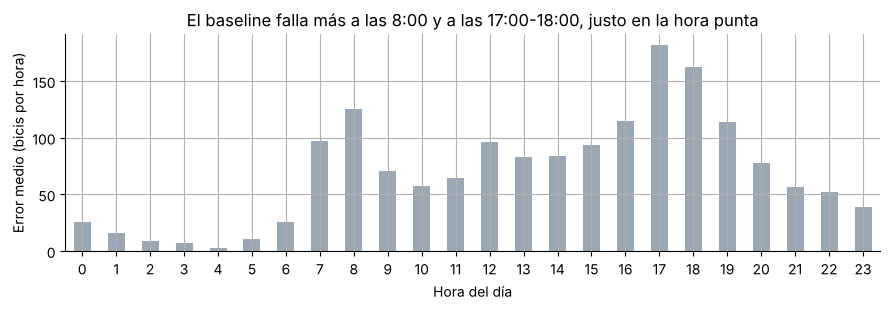

La hora donde más falla: 17:00 con 182 bicis de error medio


In [4]:
# ¿Dónde falla el baseline? Por hora del día y por tipo de día
err = (y_val - pred_semana).abs()
por_hora = err.groupby(y_val.index.hour).mean()
fig, ax = plt.subplots(figsize=(9, 3.2))
por_hora.plot.bar(ax=ax, color="#9aa7b4", rot=0)
ax.set_title("El baseline falla más a las 8:00 y a las 17:00-18:00, justo en la hora punta")
ax.set_xlabel("Hora del día"); ax.set_ylabel("Error medio (bicis por hora)")
plt.tight_layout(); plt.show()
peor_hora = int(por_hora.idxmax())
print(f"La hora donde más falla: {peor_hora}:00 con {por_hora.max():.0f} bicis de error medio")

## 4. Cifras para la ficha

In [5]:
import json, sys, sklearn
cifras = {
    "n_ent": int(m_ent.sum()), "n_val": int(m_val.sum()), "n_test": int(m_test.sum()),
    "tramos": {"ent": [str(x.index[m_ent].min().date()), str(x.index[m_ent].max().date())],
               "val": [str(x.index[m_val].min().date()), str(x.index[m_val].max().date())],
               "test": [str(x.index[m_test].min().date()), str(x.index[m_test].max().date())]},
    "semana": {k: round(v, 3) for k, v in res_semana.items()}, "media4": {k: round(v, 3) for k, v in res_media4.items()},
    "objetivo": round(objetivo, 1), "nivel_val": round(float(y_val.mean()), 1), "peor_hora": peor_hora, "err_peor_hora": round(float(por_hora.max())),
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}",
}
print(json.dumps(cifras, ensure_ascii=False))

{"n_ent": 13944, "n_val": 1464, "n_test": 1464, "tramos": {"ent": ["2011-01-29", "2012-08-31"], "val": ["2012-09-01", "2012-10-31"], "test": ["2012-11-01", "2012-12-31"]}, "semana": {"MAE": 69.499, "WAPE": 0.244, "MAE hora punta": 132.695}, "media4": {"MAE": 57.647, "WAPE": 0.202, "MAE hora punta": 103.284}, "objetivo": 52.1, "nivel_val": 285.1, "peor_hora": 17, "err_peor_hora": 182, "versiones": "Python 3.13.18, numpy 2.5.3, pandas 2.3.3, scikit-learn 1.9.1"}
